# Expérimentation complémentaire — Impact du scaling

## Objectif

Lors de la phase de prétraitement, la standardisation des variables numériques avait été identifiée comme une transformation pouvant être appliquée lors de la modélisation pour les algorithmes sensibles à l'échelle des variables.

L'objectif de cette expérimentation complémentaire est d'évaluer l'impact d'une standardisation des variables sur les performances de plusieurs modèles :

- Régression linéaire ;
- Ridge ;
- Lasso ;
- Perceptron Multicouche (MLP).

Les modèles fondés sur les arbres, tels que l'Arbre de décision, Random Forest, XGBoost et LightGBM, ne sont pas concernés par cette expérimentation car leur fonctionnement est peu sensible à l'échelle des variables.

Afin d'isoler l'effet du scaling, les mêmes jeux d'entraînement et de test ainsi que les mêmes configurations de modèles seront conservés autant que possible.

La standardisation sera ajustée uniquement sur le jeu d'entraînement afin d'éviter toute fuite d'information vers le jeu de test.

## 1. Préparation des données

Afin de comparer correctement les performances obtenues avec et sans standardisation, cette expérimentation reprend exactement les mêmes jeux d'entraînement et de test que la modélisation principale.

Les jeux de données déjà préparés lors de la phase de prétraitement sont directement réutilisés. Ils correspondent à une séparation de 80 % des observations pour l'entraînement et 20 % pour le test, réalisée avec `random_state=42`.

Cette approche permet de conserver exactement les mêmes observations et les mêmes variables que dans la modélisation principale. La seule différence introduite dans cette expérimentation sera donc l'application du scaling.

Afin d'éviter toute fuite d'information, le scaler sera ajusté uniquement sur le jeu d'entraînement puis appliqué au jeu de test.

In [8]:
# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt

In [2]:
# ============================================================
# CHARGEMENT DES JEUX DE DONNÉES
# ============================================================

X_train = pd.read_csv("../data/X_train_final.csv")
X_test = pd.read_csv("../data/X_test_final.csv")

y_train = pd.read_csv("../data/y_train.csv")["co2"]
y_test = pd.read_csv("../data/y_test.csv")["co2"]

In [3]:
# Vérification des dimensions

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)
print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test  :", y_test.shape)

Dimensions de X_train : (44002, 93)
Dimensions de X_test  : (11001, 93)
Dimensions de y_train : (44002,)
Dimensions de y_test  : (11001,)


## 2. Standardisation des variables

La standardisation consiste à transformer les variables afin qu'elles soient exprimées sur une échelle comparable, avec une moyenne proche de 0 et un écart-type proche de 1.

Le `StandardScaler` est ajusté uniquement sur le jeu d'entraînement (`X_train`). Les paramètres appris sur ce jeu sont ensuite utilisés pour transformer `X_train` et `X_test`.

Cette méthode permet d'éviter toute fuite d'information du jeu de test vers le jeu d'entraînement.

In [4]:
# ============================================================
# STANDARDISATION DES VARIABLES
# ============================================================

# Création du scaler
scaler = StandardScaler()

# Apprentissage uniquement sur X_train
X_train_scaled = scaler.fit_transform(X_train)

# Application au jeu de test avec les paramètres appris sur X_train
X_test_scaled = scaler.transform(X_test)

In [5]:
# Vérification des dimensions après standardisation

print("Dimensions de X_train_scaled :", X_train_scaled.shape)
print("Dimensions de X_test_scaled  :", X_test_scaled.shape)

# Vérification de la standardisation sur X_train
print("\nMoyenne globale de X_train_scaled :", X_train_scaled.mean())
print("Écart-type global de X_train_scaled :", X_train_scaled.std())

Dimensions de X_train_scaled : (44002, 93)
Dimensions de X_test_scaled  : (11001, 93)

Moyenne globale de X_train_scaled : 5.736868262956207e-18
Écart-type global de X_train_scaled : 0.9999999999999998


## 3. Régression linéaire avec standardisation

La régression linéaire est réentraînée sur les variables standardisées afin de mesurer l'impact du scaling sur ses performances.

Les résultats obtenus seront comparés à ceux de la modélisation principale réalisée sans standardisation.

In [6]:
# ============================================================
# RÉGRESSION LINÉAIRE AVEC STANDARDISATION
# ============================================================

linear_scaled = LinearRegression()

# Entraînement
linear_scaled.fit(X_train_scaled, y_train)

# Prédictions
y_pred_linear_scaled = linear_scaled.predict(X_test_scaled)

# Métriques
mae_linear_scaled = mean_absolute_error(y_test, y_pred_linear_scaled)
rmse_linear_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_linear_scaled)
)
r2_linear_scaled = r2_score(y_test, y_pred_linear_scaled)
mape_linear_scaled = mean_absolute_percentage_error(
    y_test,
    y_pred_linear_scaled
)

print(f"MAE  : {mae_linear_scaled:.4f}")
print(f"RMSE : {rmse_linear_scaled:.4f}")
print(f"R²   : {r2_linear_scaled:.4f}")
print(f"MAPE : {mape_linear_scaled:.4f}")

MAE  : 1.0922
RMSE : 1.7402
R²   : 0.9974
MAPE : 0.0059


### Interprétation

La standardisation n'a pas modifié les performances de la régression linéaire. Les quatre métriques obtenues sont identiques à celles du modèle entraîné sans scaling.

Ce résultat montre que, dans cette expérimentation, le changement d'échelle des variables n'apporte pas de gain prédictif à la régression linéaire. La standardisation modifie l'échelle des coefficients du modèle, mais pas sa capacité prédictive.

## 4. Régression Ridge avec standardisation

La régression Ridge ajoute une pénalisation L2 à la régression linéaire afin de limiter l'amplitude des coefficients.

Contrairement à la régression linéaire classique, la régularisation est sensible à l'échelle des variables. La standardisation permet donc d'appliquer la pénalisation de manière plus homogène entre les différentes variables.

Dans un premier temps, le modèle est entraîné avec `alpha=1`, correspondant à la configuration initiale utilisée dans la modélisation principale, afin d'isoler l'effet du scaling.

In [7]:
# ============================================================
# RIDGE AVEC STANDARDISATION
# ============================================================

ridge_scaled = Ridge(alpha=1.0)

# Entraînement
ridge_scaled.fit(X_train_scaled, y_train)

# Prédictions
y_pred_ridge_scaled = ridge_scaled.predict(X_test_scaled)

# Métriques
mae_ridge_scaled = mean_absolute_error(
    y_test,
    y_pred_ridge_scaled
)

rmse_ridge_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_ridge_scaled)
)

r2_ridge_scaled = r2_score(
    y_test,
    y_pred_ridge_scaled
)

mape_ridge_scaled = mean_absolute_percentage_error(
    y_test,
    y_pred_ridge_scaled
)

print(f"MAE  : {mae_ridge_scaled:.4f}")
print(f"RMSE : {rmse_ridge_scaled:.4f}")
print(f"R²   : {r2_ridge_scaled:.4f}")
print(f"MAPE : {mape_ridge_scaled:.4f}")

MAE  : 1.0925
RMSE : 1.7401
R²   : 0.9974
MAPE : 0.0060


### Interprétation

La régression Ridge avec standardisation (`alpha=1`) obtient de très bonnes performances prédictives, avec une MAE de **1,0925 g/km**, une RMSE de **1,7401 g/km** et un coefficient de détermination R² de **0,9974**. La MAPE atteint **0,0060**, soit environ **0,60 %**.

Ces résultats montrent que le modèle explique une très grande partie de la variabilité des émissions de CO₂ et présente des erreurs de prédiction relativement faibles.

La standardisation est particulièrement pertinente pour Ridge, car la régularisation L2 dépend de l'échelle des variables explicatives.

Toutefois, pour déterminer si elle apporte un gain de performance, il est nécessaire de comparer ces résultats à ceux du modèle Ridge sans standardisation, évalué sur les mêmes données.

### Optimisation de Ridge après standardisation

La valeur optimale du paramètre `alpha` peut dépendre de l'échelle des variables.

Un `GridSearchCV` est donc réalisé sur les données standardisées en utilisant la même grille de valeurs que dans la modélisation principale. Cette démarche permet de déterminer si la standardisation modifie le niveau de régularisation optimal du modèle.

In [9]:
# ============================================================
# GRIDSEARCHCV - RIDGE AVEC STANDARDISATION
# ============================================================

# Pipeline : standardisation puis régression Ridge
pipeline_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

# Même grille de valeurs que dans le notebook initial
param_grid_ridge = {
    "ridge__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_ridge_scaled = GridSearchCV(
    estimator=pipeline_ridge,
    param_grid=param_grid_ridge,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Le pipeline effectue la standardisation dans chaque pli
grid_ridge_scaled.fit(X_train, y_train)

print("Meilleur alpha :", grid_ridge_scaled.best_params_["ridge__alpha"])
print(f"Meilleur score R² CV : {grid_ridge_scaled.best_score_:.4f}")

Meilleur alpha : 1
Meilleur score R² CV : 0.9971


In [10]:
# Meilleur modèle obtenu par GridSearchCV
best_ridge_scaled = grid_ridge_scaled.best_estimator_

# Prédictions sur le jeu de test
# Le Pipeline applique automatiquement la standardisation
y_pred_best_ridge_scaled = best_ridge_scaled.predict(X_test)

# Métriques
mae_best_ridge_scaled = mean_absolute_error(
    y_test, y_pred_best_ridge_scaled
)

rmse_best_ridge_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_best_ridge_scaled)
)

r2_best_ridge_scaled = r2_score(
    y_test, y_pred_best_ridge_scaled
)

mape_best_ridge_scaled = mean_absolute_percentage_error(
    y_test, y_pred_best_ridge_scaled
)

# Affichage des performances
print(f"MAE  : {mae_best_ridge_scaled:.4f}")
print(f"RMSE : {rmse_best_ridge_scaled:.4f}")
print(f"R²   : {r2_best_ridge_scaled:.4f}")
print(f"MAPE : {mape_best_ridge_scaled:.4f}")

MAE  : 1.0925
RMSE : 1.7401
R²   : 0.9974
MAPE : 0.0060


### Interprétation de l'optimisation

Après standardisation, le `GridSearchCV` sélectionne `alpha=1`, avec un R² moyen en validation croisée de **0,9971**.

Dans la modélisation principale sans standardisation, l'optimisation avait retenu `alpha=0.0001`. Cette différence montre que la mise à l'échelle des variables influence le niveau de régularisation sélectionné par Ridge.

Le modèle optimisé obtient une **MAE de 1,0925 g/km**, une **RMSE de 1,7401 g/km**, un **R² de 0,9974** et une **MAPE de 0,0060**, soit environ **0,60 %**.

Ces performances sont identiques à celles du modèle Ridge standardisé avec `alpha=1`, ce qui est cohérent puisque le `GridSearchCV` a retenu cette même valeur.

La standardisation permet ainsi d'appliquer la régularisation L2 sur des variables placées sur une échelle comparable. Toutefois, les performances étant déjà très élevées, son intérêt doit être apprécié en comparant les résultats aux modèles sans standardisation sur les mêmes données actualisées.

## 5. Régression Lasso avec standardisation

La régression Lasso applique une pénalisation L1 pouvant conduire certains coefficients à devenir nuls et ainsi réaliser une sélection implicite de variables.

Cette pénalisation étant sensible à l'échelle des variables, le modèle est réentraîné après standardisation.

Dans un premier temps, `alpha=1` est conservé afin de comparer directement les résultats avec ceux du modèle Lasso initial de la modélisation principale.

In [11]:
# ============================================================
# LASSO AVEC STANDARDISATION
# ============================================================

lasso_scaled = Lasso(alpha=1.0)

# Entraînement
lasso_scaled.fit(X_train_scaled, y_train)

# Prédictions
y_pred_lasso_scaled = lasso_scaled.predict(X_test_scaled)

# Métriques
mae_lasso_scaled = mean_absolute_error(
    y_test, y_pred_lasso_scaled
)

rmse_lasso_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_lasso_scaled)
)

r2_lasso_scaled = r2_score(
    y_test, y_pred_lasso_scaled
)

mape_lasso_scaled = mean_absolute_percentage_error(
    y_test, y_pred_lasso_scaled
)

print(f"MAE  : {mae_lasso_scaled:.4f}")
print(f"RMSE : {rmse_lasso_scaled:.4f}")
print(f"R²   : {r2_lasso_scaled:.4f}")
print(f"MAPE : {mape_lasso_scaled:.4f}")

MAE  : 1.9067
RMSE : 3.0057
R²   : 0.9923
MAPE : 0.0102


### Interprétation

La régression Lasso avec standardisation (`alpha=1`) obtient une MAE de **1,9067 g/km** et une RMSE de **3,0057 g/km**. Le R² atteint **0,9923**, tandis que la MAPE est de **0,0102**, soit environ **1,02 %**.

Ces résultats montrent que le modèle conserve une très bonne capacité prédictive après standardisation.

La mise à l'échelle des variables est particulièrement importante pour Lasso, car la pénalisation L1 agit directement sur les coefficients et peut être fortement influencée lorsque les variables sont exprimées sur des échelles différentes.

Malgré ces bonnes performances, Lasso reste moins performant que la régression linéaire et Ridge avec standardisation, qui obtiennent tous deux un R² de **0,9974** et des erreurs de prédiction plus faibles.

L'effet précis de la standardisation sur Lasso sera confirmé par la comparaison avec les résultats du modèle sans scaling sur les mêmes données actualisées.

### Optimisation de Lasso après standardisation

In [12]:
# ============================================================
# GRIDSEARCHCV - LASSO AVEC STANDARDISATION
# ============================================================

# Pipeline : standardisation puis régression Lasso
pipeline_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=10000))
])

# Grille des hyperparamètres
param_grid_lasso = {
    "lasso__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

grid_lasso_scaled = GridSearchCV(
    estimator=pipeline_lasso,
    param_grid=param_grid_lasso,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Entraînement sur les données non standardisées
# Le Pipeline réalise la standardisation dans chaque pli
grid_lasso_scaled.fit(X_train, y_train)

print("Meilleur alpha :", grid_lasso_scaled.best_params_["lasso__alpha"])
print(f"Meilleur score R² CV : {grid_lasso_scaled.best_score_:.4f}")

Meilleur alpha : 0.0001
Meilleur score R² CV : 0.9971


In [13]:
# Meilleur modèle Lasso
best_lasso_scaled = grid_lasso_scaled.best_estimator_

# Prédictions
# Le Pipeline applique automatiquement la standardisation
y_pred_best_lasso_scaled = best_lasso_scaled.predict(X_test)

# Métriques
mae_best_lasso_scaled = mean_absolute_error(
    y_test, y_pred_best_lasso_scaled
)

rmse_best_lasso_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_best_lasso_scaled)
)

r2_best_lasso_scaled = r2_score(
    y_test, y_pred_best_lasso_scaled
)

mape_best_lasso_scaled = mean_absolute_percentage_error(
    y_test, y_pred_best_lasso_scaled
)

print(f"MAE  : {mae_best_lasso_scaled:.4f}")
print(f"RMSE : {rmse_best_lasso_scaled:.4f}")
print(f"R²   : {r2_best_lasso_scaled:.4f}")
print(f"MAPE : {mape_best_lasso_scaled:.4f}")

MAE  : 1.0922
RMSE : 1.7401
R²   : 0.9974
MAPE : 0.0059


### Interprétation de l'optimisation

Après standardisation, le `GridSearchCV` sélectionne `alpha=0.0001`, avec un R² moyen en validation croisée de **0,9971**.

Le Lasso optimisé obtient une **MAE de 1,0922 g/km**, une **RMSE de 1,7401 g/km**, un **R² de 0,9974** et une **MAPE de 0,0059**, soit environ **0,59 %**.

Ces performances sont nettement meilleures que celles du Lasso standardisé avec `alpha=1`, qui obtenait une MAE de 1,9067 g/km et un R² de 0,9923.

La diminution du paramètre `alpha` réduit fortement la pénalisation L1, permettant au modèle de conserver davantage d'informations pour effectuer ses prédictions.

Après optimisation, les performances de Lasso deviennent pratiquement identiques à celles de la régression linéaire classique.

La standardisation permet d'appliquer la régularisation sur des variables placées sur une échelle comparable. Toutefois, le gain observé ici provient principalement de l'optimisation du paramètre `alpha`. Une comparaison avec le Lasso optimisé sans standardisation reste nécessaire pour isoler l'effet du scaling.

## 6. MLP avec standardisation

Les réseaux de neurones sont particulièrement sensibles à l'échelle des variables d'entrée. Des variables présentant des ordres de grandeur très différents peuvent rendre l'optimisation plus difficile.

Afin d'isoler l'effet de la standardisation, le MLP reprend la même architecture et les mêmes paramètres d'entraînement que dans la modélisation principale. La seule modification concerne l'utilisation des variables standardisées.

Une graine aléatoire identique (`seed=42`) est utilisée afin d'améliorer la reproductibilité de la comparaison.

In [14]:
# ============================================================
# MLP AVEC STANDARDISATION
# ============================================================

# Reproductibilité
tf.keras.utils.set_random_seed(42)

# Architecture identique au MLP initial
mlp_scaled = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(1)
])

# Compilation
mlp_scaled.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

mlp_scaled.summary()

E0000 00:00:1791796934.432579   10734 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,129 (31.75 KB)

 Trainable params: 8,129 (31.75 KB)

 Non-trainable params: 0 (0.00 B)

### Entraînement du MLP standardisé

In [15]:
# ============================================================
# ENTRAÎNEMENT DU MLP AVEC STANDARDISATION
# ============================================================

history_mlp_scaled = mlp_scaled.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1
)

Epoch 1/100


1101/1101 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 5552.4688 - mae: 38.0729 - val_loss: 105.6573 - val_mae: 5.5618
Epoch 2/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 66.7539 - mae: 4.2243 - val_loss: 39.8497 - val_mae: 3.3351
Epoch 3/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 31.6011 - mae: 2.8336 - val_loss: 23.8992 - val_mae: 2.4933
Epoch 4/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 19.6139 - mae: 2.1651 - val_loss: 16.8703 - val_mae: 2.0209
Epoch 5/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 14.1212 - mae: 1.7593 - val_loss: 12.4005 - val_mae: 1.6752
Epoch 6/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 11.2460 - mae: 1.4967 - val_loss: 10.5738 - val_mae: 1.4701
Epoch 7/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 9.3857 - mae: 1.3156 - val_loss: 8.3528 - val_mae: 1.2737
Epoch 8/100
1101/1101 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 8.4697 - mae: 1.2109 - val_loss: 8.0606 - val_mae: 1.2375
Epoch 9/100
1101/1101 ━━━━━━

In [16]:
# ============================================================
# ÉVALUATION DU MLP AVEC STANDARDISATION
# ============================================================

# Prédictions
y_pred_mlp_scaled = mlp_scaled.predict(X_test_scaled).flatten()

# Métriques
mae_mlp_scaled = mean_absolute_error(
    y_test, y_pred_mlp_scaled
)

rmse_mlp_scaled = np.sqrt(
    mean_squared_error(y_test, y_pred_mlp_scaled)
)

r2_mlp_scaled = r2_score(
    y_test, y_pred_mlp_scaled
)

mape_mlp_scaled = mean_absolute_percentage_error(
    y_test, y_pred_mlp_scaled
)

print(f"MAE  : {mae_mlp_scaled:.4f}")
print(f"RMSE : {rmse_mlp_scaled:.4f}")
print(f"R²   : {r2_mlp_scaled:.4f}")
print(f"MAPE : {mape_mlp_scaled:.4f}")

344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 988us/step
MAE  : 0.5726
RMSE : 1.3766
R²   : 0.9984
MAPE : 0.0034


### Interprétation

Le MLP avec standardisation obtient de très bonnes performances sur le jeu de test, avec une **MAE de 0,5726 g/km**, une **RMSE de 1,3766 g/km**, un **R² de 0,9984** et une **MAPE de 0,0034**, soit environ **0,34 %**.

Ces résultats montrent que le réseau de neurones parvient à prédire les émissions de CO₂ avec une grande précision après standardisation des variables d'entrée.

La standardisation est particulièrement adaptée aux réseaux de neurones, car elle place les variables sur des échelles comparables et facilite l'optimisation des poids du modèle.

Le MLP standardisé obtient également de meilleures performances que les modèles linéaires standardisés étudiés précédemment, notamment la régression linéaire, Ridge et Lasso optimisé, qui atteignent un R² de 0,9974.

Toutefois, le MLP standardisé reste légèrement moins performant que les meilleurs modèles d'ensemble de la modélisation principale, notamment XGBoost et Random Forest.

Pour mesurer précisément le gain apporté par la standardisation, ces résultats devront être comparés à ceux du MLP sans standardisation sur les mêmes données actualisées.

### Courbe d'apprentissage du MLP standardisé

Les courbes de la fonction de coût sur les jeux d'entraînement et de validation permettent d'observer la convergence du modèle au cours des epochs et d'identifier un éventuel sur-apprentissage.

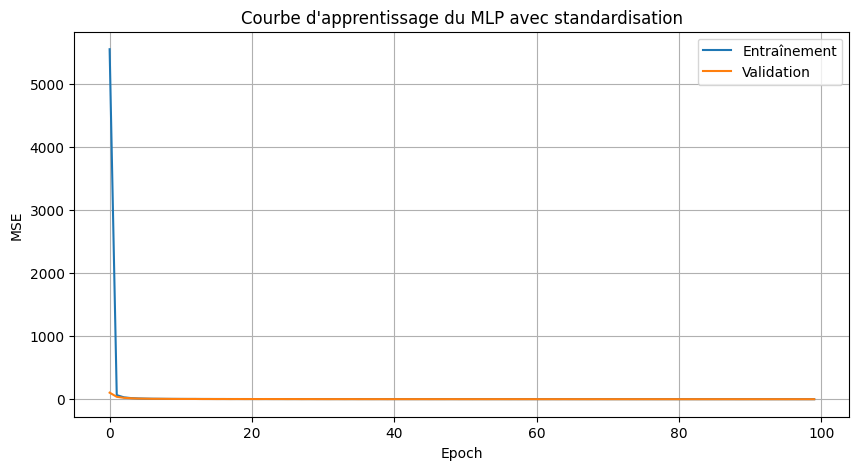

In [17]:
# ============================================================
# COURBE D'APPRENTISSAGE DU MLP STANDARDISÉ
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_mlp_scaled.history["loss"],
    label="Entraînement"
)

plt.plot(
    history_mlp_scaled.history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage du MLP avec standardisation")
plt.legend()
plt.grid(True)

plt.show()

### Interprétation de la courbe d'apprentissage

La courbe d'apprentissage montre une **forte diminution de la fonction de coût (MSE)** dès les premières epochs.

Cependant, les erreurs initiales étant particulièrement élevées, l'échelle du graphique rend difficile l'observation des variations au cours des epochs suivantes.

Un second graphique, débutant à la cinquième epoch, permet donc d'analyser plus précisément la convergence du modèle et l'évolution des erreurs d'entraînement et de validation.

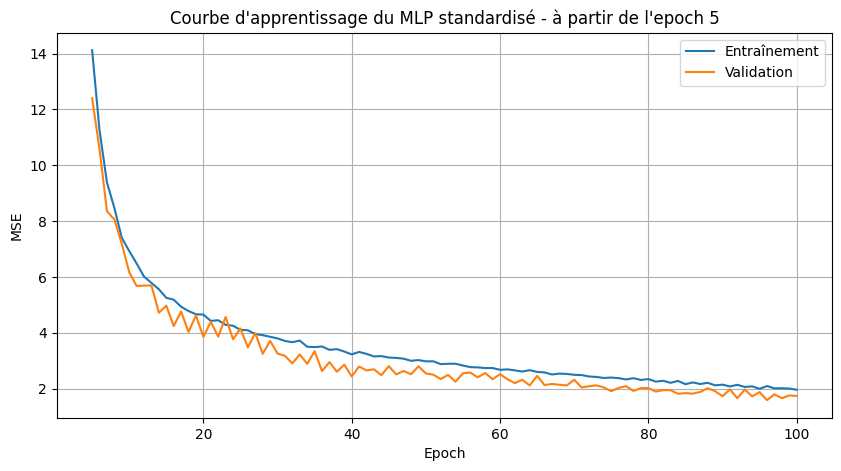

In [18]:
# ============================================================
# COURBE D'APPRENTISSAGE DU MLP STANDARDISÉ - ZOOM
# ============================================================

start_epoch = 5

plt.figure(figsize=(10, 5))

plt.plot(
    range(start_epoch, 101),
    history_mlp_scaled.history["loss"][start_epoch - 1:],
    label="Entraînement"
)

plt.plot(
    range(start_epoch, 101),
    history_mlp_scaled.history["val_loss"][start_epoch - 1:],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Courbe d'apprentissage du MLP standardisé - à partir de l'epoch 5")
plt.legend()
plt.grid(True)

plt.show()

### Analyse de la courbe d'apprentissage

La courbe d'apprentissage du MLP standardisé montre une **diminution rapide de l'erreur au cours des premières epochs**, suivie d'une convergence plus progressive.

La fonction de coût (MSE) sur le jeu d'entraînement continue de diminuer jusqu'à la fin de l'apprentissage, pour atteindre environ **1,96** à la dernière epoch.

L'erreur de validation suit une évolution similaire, malgré quelques fluctuations, et atteint environ **1,74** en fin d'entraînement.

Les deux courbes restent proches et aucune remontée durable de l'erreur de validation n'est observée. Le modèle ne présente donc **pas de signe marqué de surapprentissage** sur cette expérimentation.

Ces observations confirment que le MLP standardisé converge correctement et parvient à généraliser ses prédictions sur les données de validation.

Elles sont également cohérentes avec les performances obtenues sur le jeu de test, notamment un **R² de 0,9984** et une **MAE de 0,5726 g/km**.

## 7. Comparaison finale des performances

Les résultats obtenus avec standardisation sont comparés aux performances de référence issues de la modélisation principale.

Pour Ridge et Lasso, les résultats des modèles optimisés sont retenus afin de comparer les meilleures configurations obtenues avec et sans standardisation.

In [19]:
# ============================================================
# TABLEAU COMPARATIF - SANS / AVEC STANDARDISATION
# ============================================================

# Résultats sans standardisation :
# issus du notebook principal actualisé après suppression des doublons

comparaison_scaling = pd.DataFrame({
    "Modèle": [
        "Régression linéaire",
        "Régression linéaire",
        "Ridge optimisé",
        "Ridge optimisé",
        "Lasso optimisé",
        "Lasso optimisé",
        "MLP",
        "MLP"
    ],

    "Scaling": [
        "Sans",
        "Avec",
        "Sans",
        "Avec",
        "Sans",
        "Avec",
        "Sans",
        "Avec"
    ],

    "MAE": [
        1.0922,
        mae_linear_scaled,
        1.0925,
        mae_best_ridge_scaled,
        1.0922,
        mae_best_lasso_scaled,
        0.5863,
        mae_mlp_scaled
    ],

    "RMSE": [
        1.7402,
        rmse_linear_scaled,
        1.7401,
        rmse_best_ridge_scaled,
        1.7401,
        rmse_best_lasso_scaled,
        1.5947,
        rmse_mlp_scaled
    ],

    "R²": [
        0.9974,
        r2_linear_scaled,
        0.9974,
        r2_best_ridge_scaled,
        0.9974,
        r2_best_lasso_scaled,
        0.9978,
        r2_mlp_scaled
    ],

    "MAPE": [
        0.0059,
        mape_linear_scaled,
        0.0060,
        mape_best_ridge_scaled,
        0.0059,
        mape_best_lasso_scaled,
        0.0034,
        mape_mlp_scaled
    ]
})

# Affichage du tableau comparatif
display(comparaison_scaling.round(4))

,Modèle,Scaling,MAE,RMSE,R²,MAPE
0,Régression linéaire,Sans,1.0922,1.7402,0.9974,0.0059
1,Régression linéaire,Avec,1.0922,1.7402,0.9974,0.0059
2,Ridge optimisé,Sans,1.0925,1.7401,0.9974,0.0060
3,Ridge optimisé,Avec,1.0925,1.7401,0.9974,0.0060
4,Lasso optimisé,Sans,1.0922,1.7401,0.9974,0.0059
5,Lasso optimisé,Avec,1.0922,1.7401,0.9974,0.0059
6,MLP,Sans,0.5863,1.5947,0.9978,0.0034
7,MLP,Avec,0.5726,1.3766,0.9984,0.0034


## 8. Conclusion de l'expérimentation

Cette expérimentation a permis d'évaluer l'impact de la standardisation sur les performances de quatre modèles de régression : la régression linéaire, Ridge, Lasso et le MLP.

### Régression linéaire

La standardisation ne modifie pas les performances de la régression linéaire. Les résultats sont identiques avec et sans scaling, avec une **MAE de 1,0922 g/km**, une **RMSE de 1,7402 g/km** et un **R² de 0,9974**.

Ce résultat est cohérent avec le fonctionnement de la régression linéaire classique, dont les prédictions ne dépendent pas de l'échelle des variables lorsque le modèle est correctement ajusté.

### Ridge et Lasso

Pour les modèles régularisés, l'effet de la standardisation est principalement visible sur le choix du paramètre de régularisation.

Pour **Ridge**, le meilleur `alpha` passe de `0.0001` sans standardisation à `1` après standardisation. Malgré cette différence, les performances restent identiques à quatre décimales, avec une **MAE de 1,0925 g/km** et un **R² de 0,9974**.

Pour **Lasso**, le `GridSearchCV` sélectionne `alpha=0.0001` après standardisation, soit la même valeur que dans la modélisation principale. Les performances du modèle optimisé restent également identiques à quatre décimales, avec une **MAE de 1,0922 g/km** et un **R² de 0,9974**.

Ces résultats montrent que la standardisation permet d'appliquer les pénalisations L1 et L2 sur des variables placées sur une échelle comparable, sans apporter ici de gain prédictif notable après optimisation.

### MLP

L'amélioration la plus importante concerne le réseau de neurones MLP.

Après standardisation :

- La **MAE** diminue de **0,5863 à 0,5726 g/km**.
- La **RMSE** diminue de **1,5947 à 1,3766 g/km**.
- Le **R²** progresse de **0,9978 à 0,9984**.
- La **MAPE** reste stable à **0,0034**, soit environ **0,34 %**.

La réduction de la RMSE est particulièrement intéressante : elle traduit une diminution des erreurs quadratiques, davantage sensibles aux écarts de prédiction importants.

Ces résultats confirment l'intérêt de la standardisation pour le MLP. La mise à l'échelle des variables facilite l'optimisation des poids du réseau et permet d'améliorer sa précision prédictive dans cette expérimentation.

### Bilan général

L'impact de la standardisation dépend du type de modèle utilisé.

Pour la régression linéaire, Ridge et Lasso optimisés, les performances restent pratiquement inchangées.

En revanche, le **MLP bénéficie de la standardisation**, avec une amélioration de la MAE, de la RMSE et du R².

La standardisation constitue donc une étape pertinente pour les réseaux de neurones et, plus généralement, pour les modèles sensibles à l'échelle des variables.

Les modèles fondés sur les arbres, notamment Random Forest, XGBoost et LightGBM, n'ont pas été réentraînés dans cette expérimentation, car leur fonctionnement est généralement peu sensible aux transformations linéaires de l'échelle des variables.

Cette expérimentation montre ainsi que la standardisation ne doit pas être appliquée systématiquement dans l'objectif d'améliorer les performances, mais choisie en fonction des caractéristiques du modèle utilisé.